In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-02-19,24632.05,25192.00,24192.57,24271.76,300395.99542,7660484.0,7.291140e+09,21314.1768,19728.50975,...,3.576975,0.250004,-2.490002,0.076967,0.660004,63.456159,1.224956,1,3.252710,1
1,2023-02-20,24272.51,25121.23,23840.83,24842.20,346938.56997,9808728.0,8.618717e+09,21478.6858,19739.60585,...,3.581932,0.080004,-1.590002,0.076908,0.575005,60.909118,-1.421748,-1,3.293558,1
2,2023-02-21,24843.89,25250.00,24148.34,24452.16,376000.82868,10712371.0,9.194032e+09,21634.2716,19745.30455,...,3.587766,-0.089996,-2.440002,0.076849,0.490005,67.942746,-3.491317,-1,3.587327,1
3,2023-02-22,24450.67,24476.05,23574.69,24182.21,379425.75365,11395957.0,9.175353e+09,21784.4122,19751.44455,...,3.591957,0.070000,-1.970006,0.393546,0.589996,73.790362,-3.735558,-1,3.869010,1
4,2023-02-23,24182.21,24599.59,23608.00,23940.20,398400.45437,11396877.0,9.537787e+09,21926.2090,19755.27360,...,3.596035,0.349998,-1.900004,0.009563,0.470001,80.000199,-4.251431,-1,4.179378,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,2025-02-13,97870.00,98083.91,95217.36,96608.14,19921.77616,3909456.0,1.924606e+09,98686.2298,79550.34745,...,2.868104,-0.885002,2.829999,-0.583662,0.970001,44.367741,0.072062,1,-11.183009,-1
726,2025-02-14,96608.13,98826.00,96252.82,97500.48,18173.02646,3499564.0,1.771879e+09,98720.4074,79703.92640,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-0.269026,-1,-11.589417,-1
727,2025-02-15,97500.47,97972.26,97223.58,97569.66,7349.37683,1694327.0,7.170762e+08,98785.8200,79860.83470,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-0.584173,-1,-11.968225,-1
728,2025-02-16,97569.67,97704.47,96046.18,96118.12,8191.42490,1596701.0,7.873444e+08,98802.1824,80018.28530,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-0.513100,-1,-12.180916,-1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 94 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   timestamp                    730 non-null    object 
 1   open_binance                 730 non-null    float64
 2   high_binance                 730 non-null    float64
 3   low_binance                  730 non-null    float64
 4   close_binance                730 non-null    float64
 5   volume_binance               730 non-null    float64
 6   trades_binance               730 non-null    float64
 7   volumen_binance              730 non-null    float64
 8   SMA_50_binance               730 non-null    float64
 9   SMA_200_binance              730 non-null    float64
 10  EMA_50_binance               730 non-null    float64
 11  EMA_200_binance              730 non-null    float64
 12  var_diaria_binance           730 non-null    float64
 13  volatilidad_50_binan

## 1. Conteo de nulos

<Axes: >

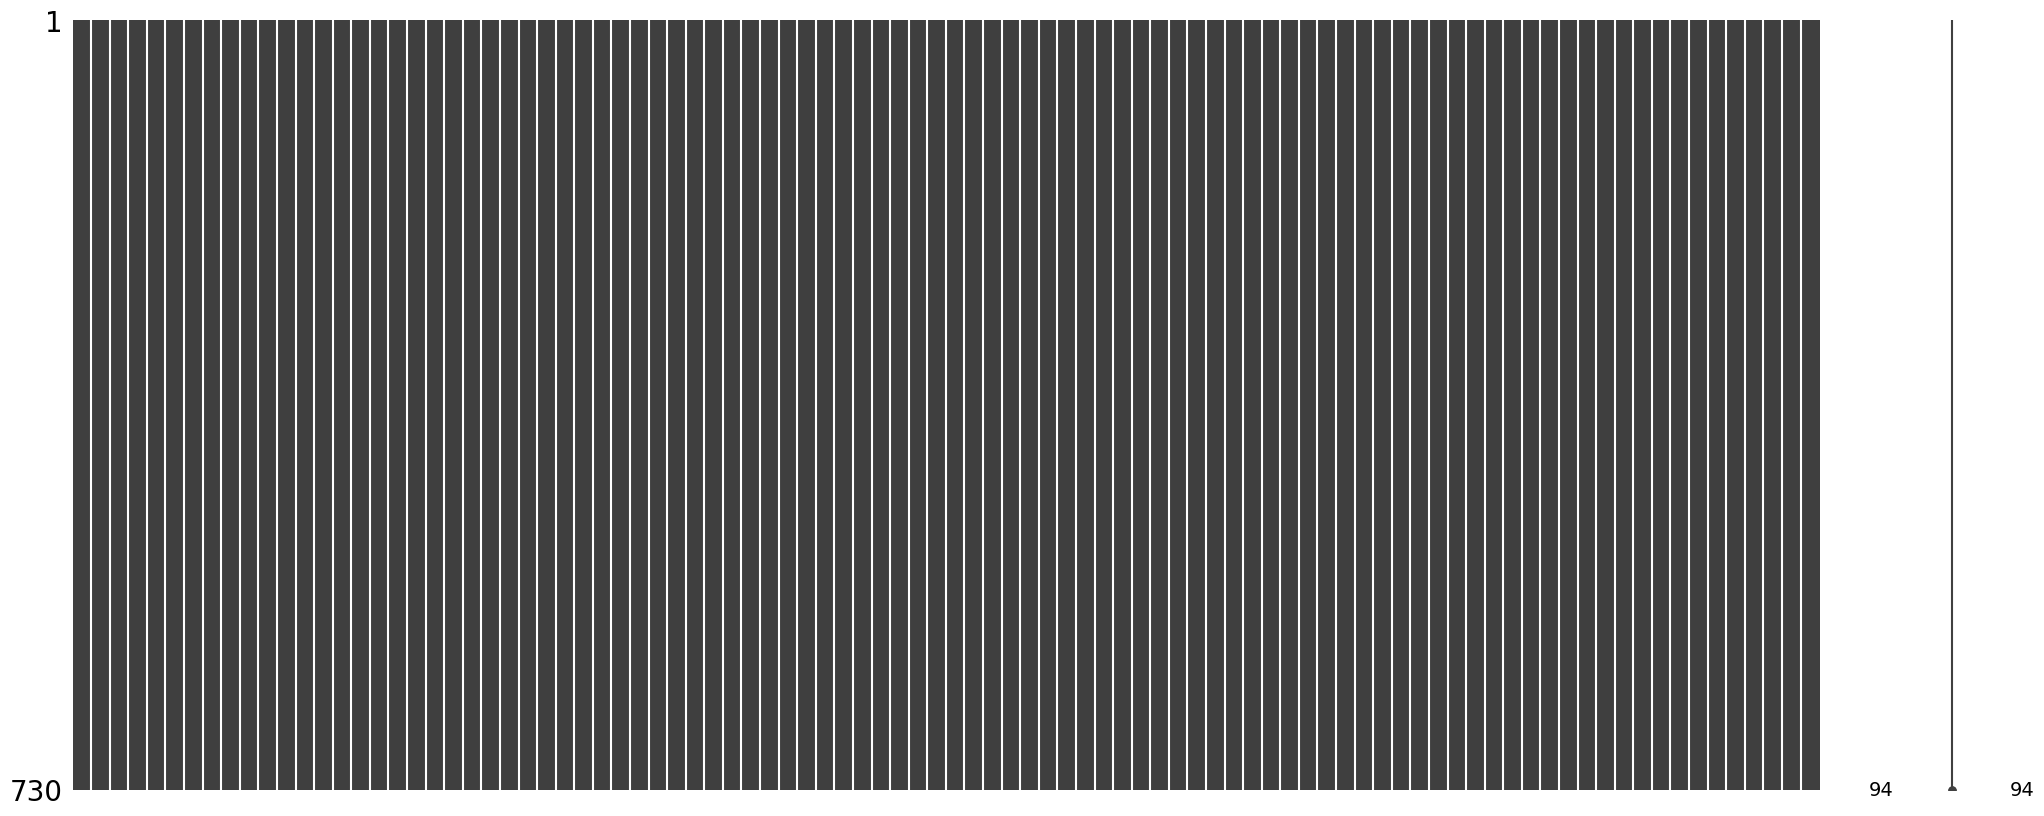

In [4]:
msno.matrix(df)

## 2. Correlaciones

### Relación precios de Bitcoin con otros activos (S&P 500, DXY, Nasdaq)

In [5]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy']].dropna().corr(method='pearson')

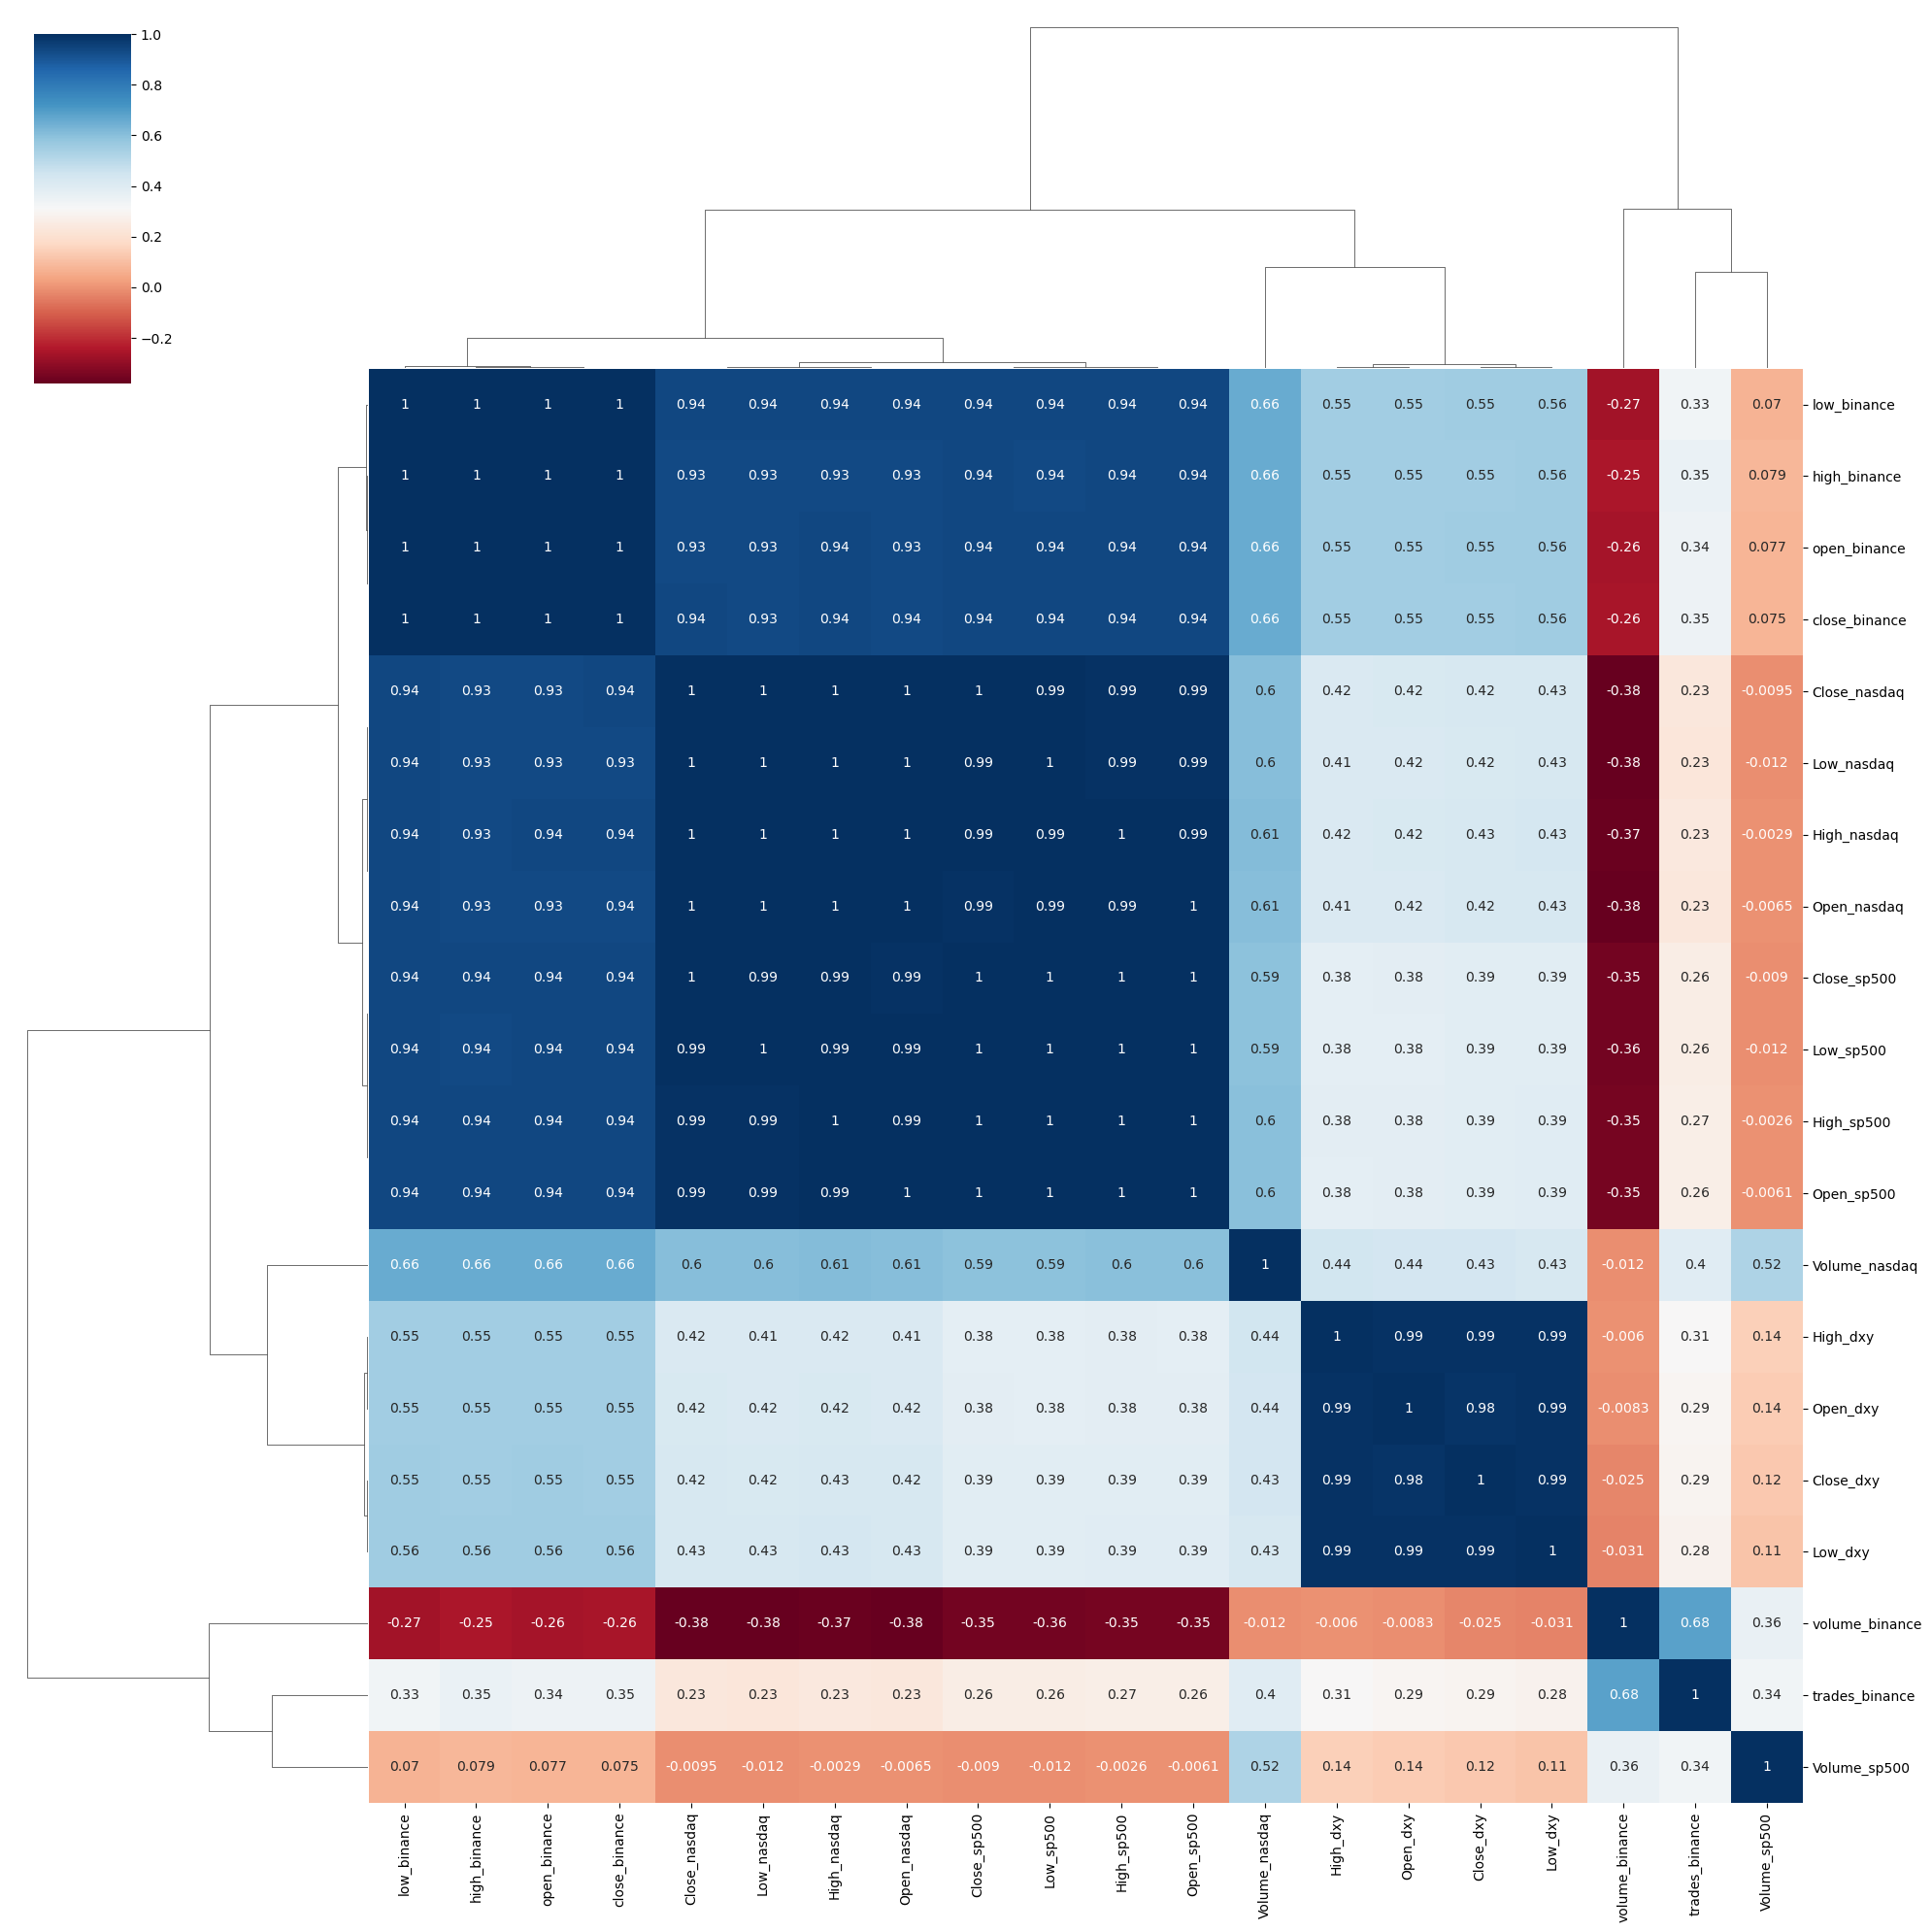

In [6]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Tendencias en sentimientos del mercado (Fear & Greed Index, Google Trends)

In [7]:
corr_matrix = df[["close_binance", "volatilidad_50_binance", "volatilidad_200_binance", "var_diaria_binance",
                  "fear_greed_index_fg", "bitcoin_gtrends",
                  "Close_sp500", "Close_nasdaq", "Close_dxy"]].dropna().corr(method='spearman')

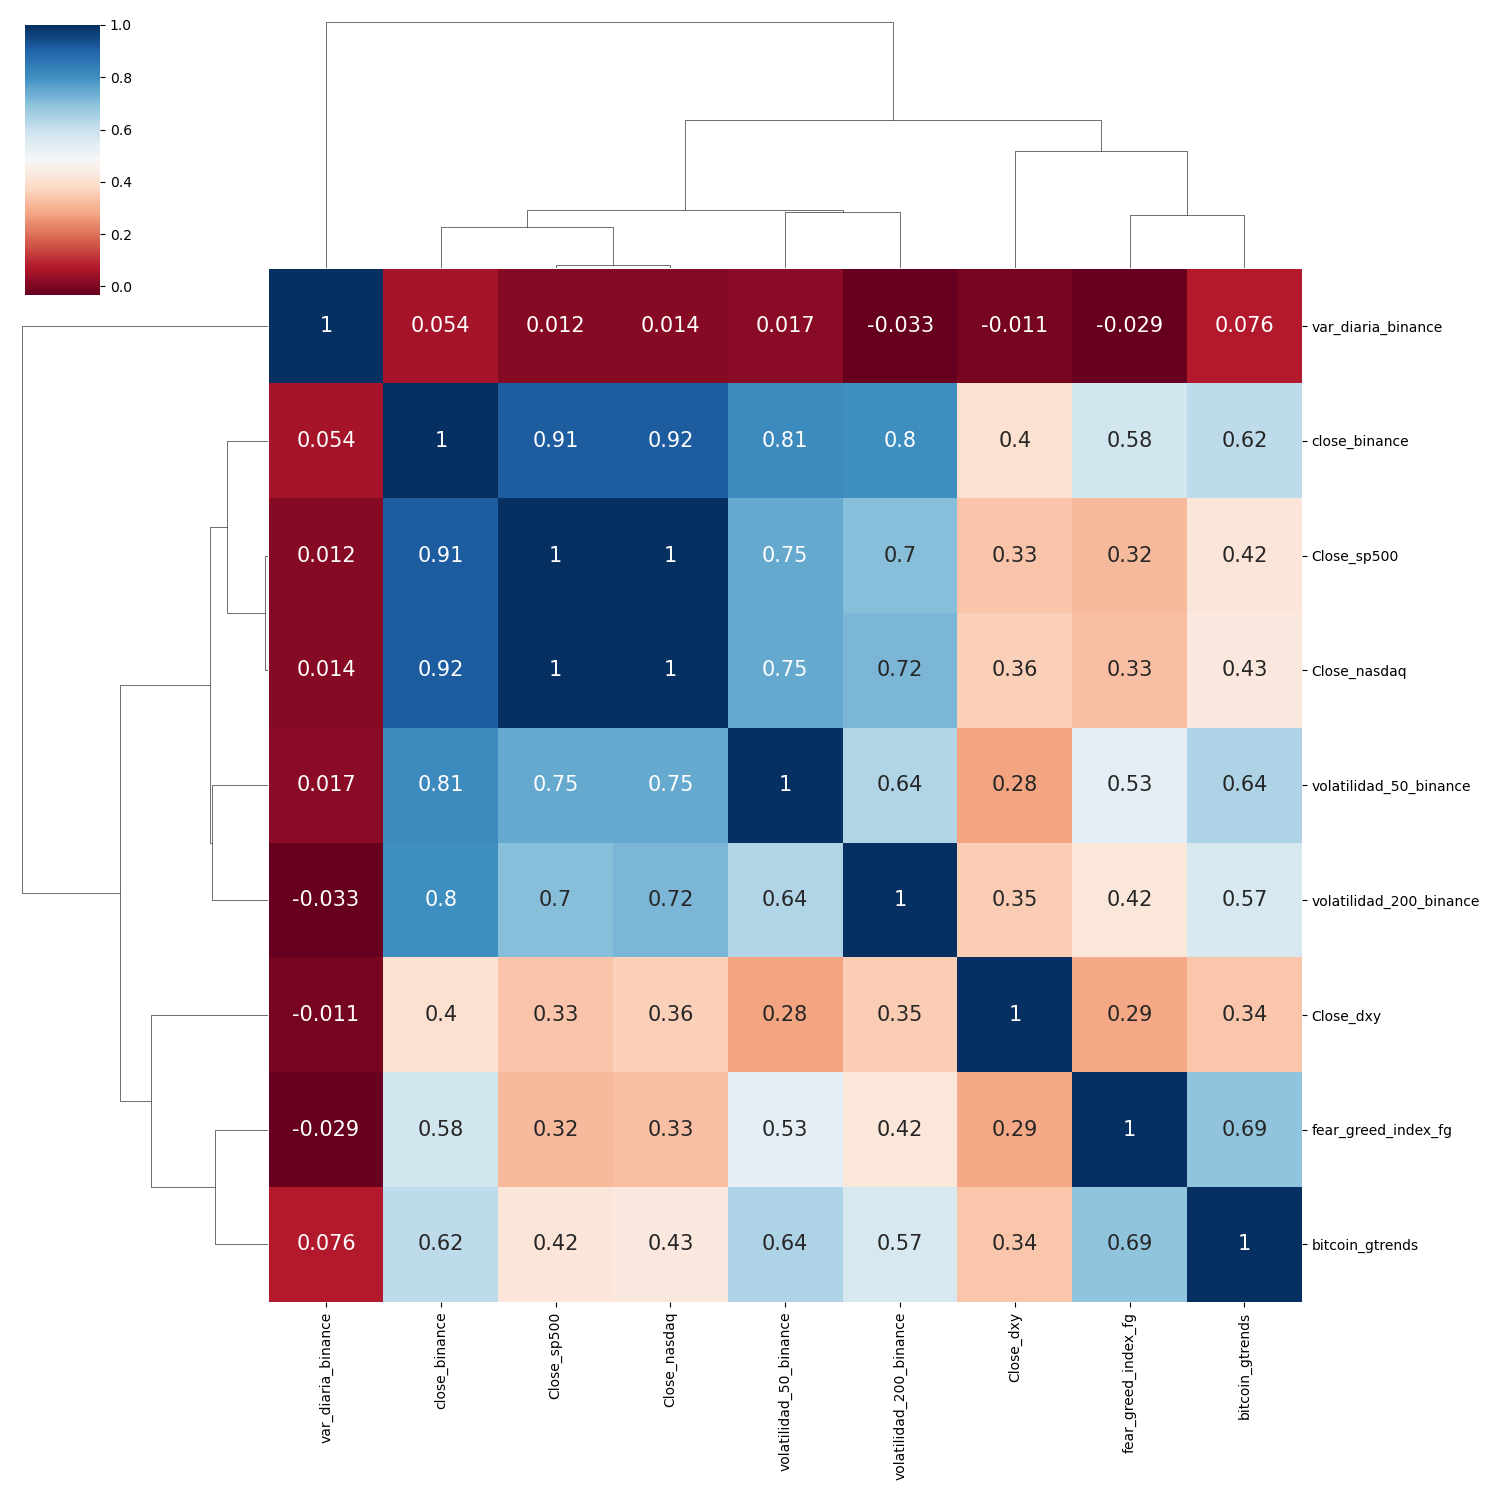

In [8]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 15}, # Tamaño de la fuente de las anotaciones
                   figsize=(15, 15))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()

### Relación entre volatilidad y precio

In [9]:
df_filtered = df[['close_binance', 'volatilidad_50_binance', 'volatilidad_200_binance', 'var_diaria_binance']].dropna()

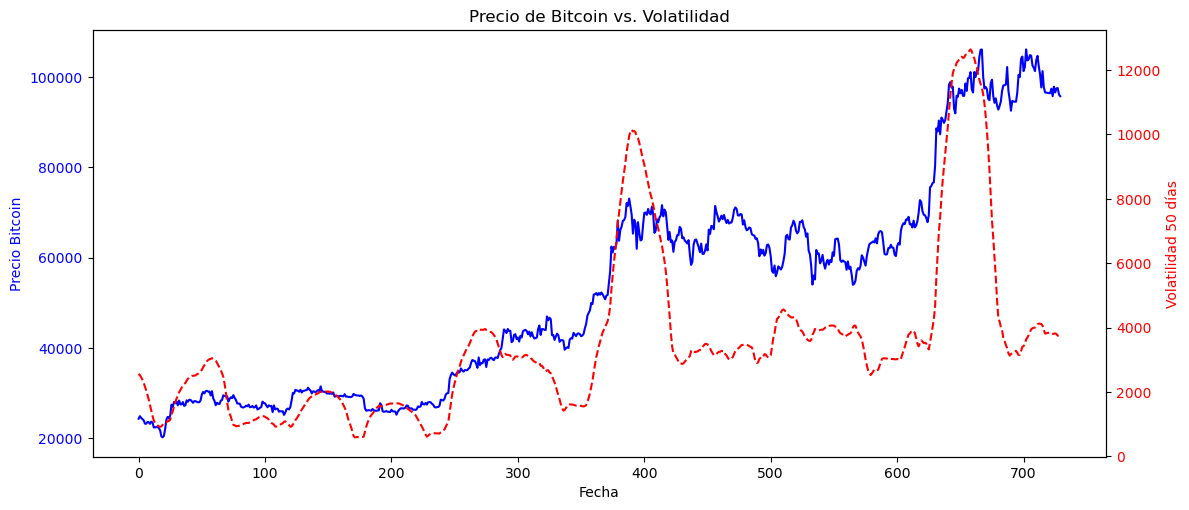

In [10]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfica de precio (eje izquierdo)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Precio Bitcoin', color='blue')
ax1.plot(df_filtered.index, df_filtered['close_binance'], color='blue', label='Precio BTC')
ax1.tick_params(axis='y', labelcolor='blue')

# Agregar segundo eje Y para volatilidad
ax2 = ax1.twinx()
ax2.set_ylabel('Volatilidad 50 días', color='red')
ax2.plot(df_filtered.index, df_filtered['volatilidad_50_binance'], color='red', linestyle='dashed', label='Volatilidad 50 días')
ax2.tick_params(axis='y', labelcolor='red')

fig.tight_layout()
plt.title("Precio de Bitcoin vs. Volatilidad")
plt.show()

In [11]:
corr_matrix = df_filtered.corr(method='spearman')  # Spearman capta relaciones no lineales

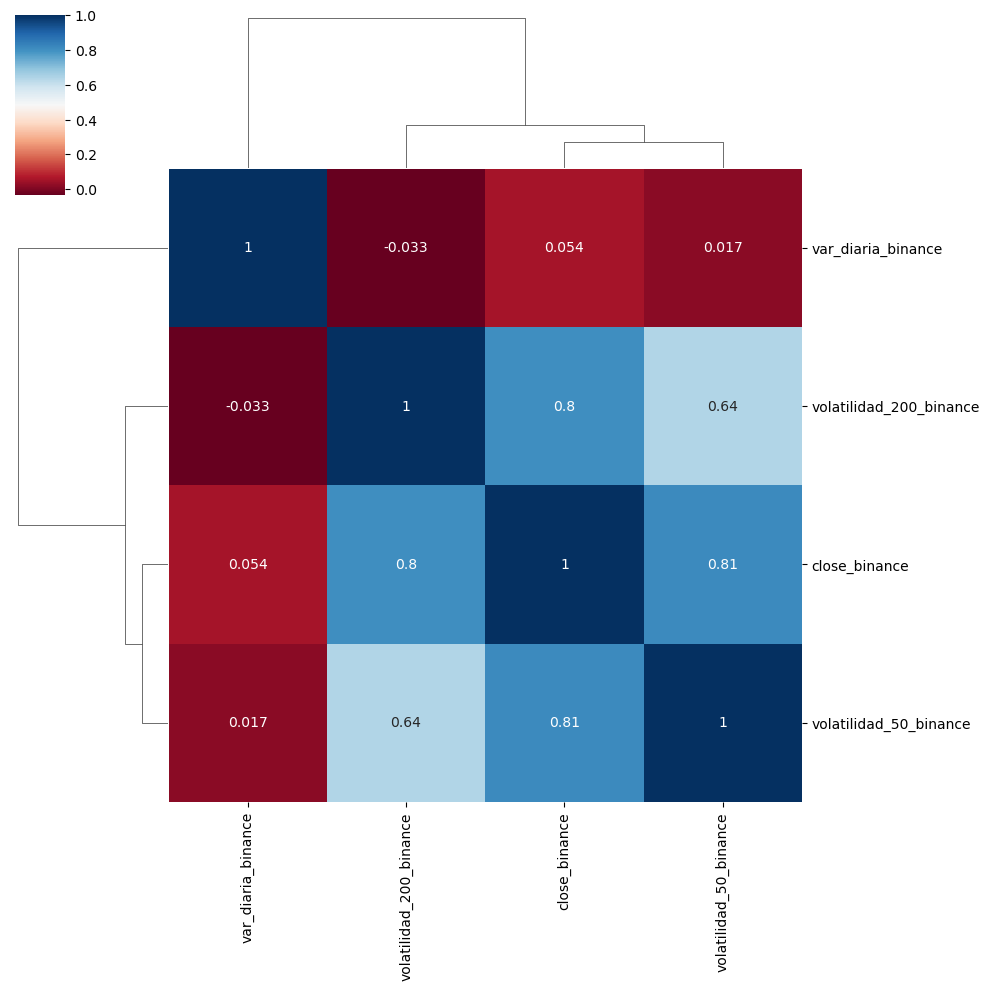

In [12]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(10, 10))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()